# 04 — Feature Engineering and Encoding
**Day 4 · Phase 2**

### Objectives
1. Extract numeric information from text (`model`, `processor`).
2. Choose an encoding for each categorical variable, and justify it with evidence rather than defaulting to one-hot.
3. Check redundancy and multicollinearity.
4. Build the **reusable preprocessing pipeline** used by every later model and the app.
5. Create the **grouped train/test split** and lock the test set away.

### Encoding options considered
| Technique | How it works | Good for | Risk here |
|---|---|---|---|
| One-hot | One 0/1 column per category | Few categories, no order | 187 models / 275 colours → hundreds of sparse columns from 516 rows |
| Ordinal | Categories → ordered integers | Categories with a real order | Wrong if the order is invented |
| Frequency | Category → how often it appears | High cardinality | Count isn't necessarily related to price |
| Target (mean) encoding | Category → mean price | High cardinality | Leaks the target unless done out-of-fold; unstable with 1–2 rows per category |
| **Feature extraction** | Derive meaningful features from text (brand, chip tier) | Structured text | Rules need maintaining |

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plot_style import (apply_style, save_fig, rupee_axis, PALETTE, PRIMARY, ACCENT,
                            NEUTRAL, DIVERGING, SEQUENTIAL)

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

from src.preprocessing import MODEL_INPUT_COLUMNS, TARGET, GROUP_KEY
from src.feature_engineering import (SpecFeatureBuilder, make_preprocessor, extract_brand, processor_tier,
                                     processor_vendor, is_5g_model, is_premium_variant, NUMERIC_FEATURES,
                                     CATEGORICAL_FEATURES)
from src.feature_selection import variance_inflation_factors

clean = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "phones_clean.csv")
print(clean.shape)
print("Model inputs:", MODEL_INPUT_COLUMNS)

(516, 12)
Model inputs: ['model', 'processor', 'storage_gb', 'ram_gb', 'battery_mah', 'rear_camera_mp', 'front_camera_mp', 'ai_lens', 'display_size_cm']


## 1. Grouped train/test split — done first
Feature *analysis* below (encoding comparisons, Day 5 selection) must only look at training data, so the split comes
first. `GroupShuffleSplit` keeps all variants of a phone model (same `model_key`) on one side, so the test set
measures performance on **phone models the model has never seen** — the realistic use case (pricing a new phone).

In [2]:
from src.train import grouped_train_test_split
train, test = grouped_train_test_split(clean)
overlap = set(train[GROUP_KEY]) & set(test[GROUP_KEY])
print(f"Train: {len(train)} rows / {train[GROUP_KEY].nunique()} models")
print(f"Test : {len(test)} rows / {test[GROUP_KEY].nunique()} models  ({len(test)/len(clean):.1%} of rows)")
print("Models in both sets:", len(overlap))
pd.DataFrame({"train": train[TARGET].describe(), "test": test[TARGET].describe()}).T

Train: 419 rows / 137 models
Test : 97 rows / 35 models  (18.8% of rows)
Models in both sets: 0


,count,mean,std,min,25%,50%,75%,max
train,419.000,"17,038.568","10,755.275","4,999.000","9,499.000","14,490.000","20,999.000","80,999.000"
test,97.000,"15,375.722","10,486.077","5,990.000","9,999.000","12,499.000","16,990.000","79,999.000"


**Interpretation.** 419 training rows (137 models), 97 test rows (35 models), no model in both. The price
distributions are similar (medians ₹14.5k vs ₹12.5k, both reaching ~₹80k). The test set is small, so test metrics
will be noisy — cross-validation on the training set will be the main model-selection tool, and the test set is
used once for final confirmation.

## 2. Extracting features from text
### 2.1 Processor → vendor and tier
123 chipset strings → **vendor** (6 + Unknown) and an ordinal **tier**: 0 entry · 1 mainstream · 2 upper-mid ·
3 flagship. Tier follows each chip family's public positioning (e.g. Snapdragon 8-series = flagship, Helio A/P = entry)
**not** prices in this data, so it's not a disguised target encoding. Text that names no chip (`Oxygen OS`,
`Octa Core`) gets tier = NaN (imputed in the pipeline) and vendor = “Unknown”. Apple phones are mapped from the brand.

In [3]:
proc = train[["model", "processor"]].drop_duplicates("processor").copy()
proc["brand"] = proc["model"].map(extract_brand)
proc["vendor"] = [processor_vendor(p, b) for p, b in zip(proc["processor"], proc["brand"])]
proc["tier"] = [processor_tier(p, b) for p, b in zip(proc["processor"], proc["brand"])]
print("Distinct processor strings (train):", len(proc))
print("Tier coverage:", proc["tier"].notna().mean().round(3))
proc.sort_values(["tier", "vendor"]).groupby("tier", dropna=False).head(3)[["processor", "vendor", "tier"]]

Distinct processor strings (train): 95
Tier coverage: 0.958


,processor,vendor,tier
3,Mediatek Helio A22,MediaTek,0.000
4,G37,MediaTek,0.000
14,Mediatek Helio P35,MediaTek,0.000
20,Dimensity 6020,MediaTek,1.000
30,Mediatek Helio G85,MediaTek,1.000
38,Mediatek Dimensity 700,MediaTek,1.000
186,Mediatek Dimensity 1080,MediaTek,2.000
210,Mediatek Dimensity 7200 5G,MediaTek,2.000
354,Mediatek Dimensity 1080 5G,MediaTek,2.000
450,ios,Apple,3.000


**Ordinal encoding is justified for tier** because the categories have a real order (entry < mainstream < upper-mid
< flagship). Vendor has no order → one-hot.

### 2.2 Model name → brand, 5G, premium-variant flags

In [4]:
fb = SpecFeatureBuilder().fit_transform(train[MODEL_INPUT_COLUMNS])
summary = pd.DataFrame({
    "feature": ["is_5g", "is_premium_variant"],
    "share of train rows = 1": [fb["is_5g"].mean(), fb["is_premium_variant"].mean()],
    "median price when 1": [train.loc[fb["is_5g"] == 1, TARGET].median(), train.loc[fb["is_premium_variant"] == 1, TARGET].median()],
    "median price when 0": [train.loc[fb["is_5g"] == 0, TARGET].median(), train.loc[fb["is_premium_variant"] == 0, TARGET].median()],
})
display(summary)
print("Brand counts (train):"); print(fb["brand"].value_counts().to_dict())

,feature,share of train rows = 1,median price when 1,median price when 0
0,is_5g,0.382,"19,999.000","10,499.000"
1,is_premium_variant,0.189,"20,890.000","13,490.000"


Brand counts (train):
{'realme': 90, 'Redmi': 62, 'Infinix': 46, 'POCO': 46, 'vivo': 46, 'Motorola': 40, 'Samsung': 33, 'OPPO': 14, 'Tecno': 13, 'Google': 8, 'Apple': 5, 'OnePlus': 4, 'Nothing': 3, 'Nokia': 3, 'Micromax': 2, 'I Kall': 2, 'iQOO': 2}


**Model names do contain useful information**, but not as identifiers. The brand (first word), the 5G flag and the
Pro/Plus/Ultra/Max suffix generalise to unseen phones; the full model name doesn't. Brand has ~19 values, several
with only 2–5 rows, so one-hot encoding uses **`min_frequency=5`**: rare brands are pooled into an “infrequent”
column, and brands never seen in training map to it as well (`handle_unknown="infrequent_if_exist"`).

## 3. Engineered feature table

In [5]:
fb.head(8)

,storage_gb,ram_gb,battery_mah,rear_camera_mp,front_camera_mp,display_size_cm,ai_lens,processor_tier,is_5g,is_premium_variant,brand,processor_vendor
0,64.000,4.000,"6,000.000",13.000,5.000,16.760,1.000,0.000,0.000,0.000,Infinix,Unisoc
1,64.000,4.000,"6,000.000",13.000,5.000,16.760,1.000,0.000,0.000,0.000,Infinix,Unisoc
2,128.000,8.000,"5,000.000",50.000,16.000,16.640,0.000,1.000,0.000,0.000,Motorola,Qualcomm
3,32.000,2.000,"5,000.000",8.000,5.000,16.560,0.000,0.000,0.000,0.000,POCO,MediaTek
4,128.000,8.000,"5,000.000",50.000,5.000,16.760,1.000,0.000,0.000,0.000,Infinix,MediaTek
5,128.000,8.000,"5,000.000",50.000,5.000,16.760,1.000,0.000,0.000,0.000,Infinix,MediaTek
6,128.000,8.000,"5,000.000",50.000,5.000,16.760,1.000,0.000,0.000,0.000,Infinix,MediaTek
7,128.000,8.000,"5,000.000",50.000,5.000,16.760,1.000,0.000,0.000,0.000,Infinix,MediaTek


In [6]:
fb.isna().sum().to_frame("missing values (train)").T

,storage_gb,ram_gb,battery_mah,rear_camera_mp,front_camera_mp,display_size_cm,ai_lens,processor_tier,is_5g,is_premium_variant,brand,processor_vendor
missing values (train),0,14,0,0,0,0,0,9,0,0,0,0


## 4. Comparing encoding strategies (training data, grouped 5-fold CV)
To support the encoding choices with evidence, the same Ridge model (log price) is cross-validated with different
treatments of the high-cardinality columns. The frequency encoder and the raw-text one-hot are defined here only for
the comparison.

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.train import group_cv, xy
from src.evaluate import cv_summary

class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Replace each category with its training-set frequency (unseen -> 0)."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.maps_ = {c: X[c].value_counts(normalize=True) for c in X.columns}
        return self
    def transform(self, X):
        X = pd.DataFrame(X)
        return np.column_stack([X[c].map(self.maps_[c]).fillna(0).to_numpy() for c in X.columns])

class WithRaw(BaseEstimator, TransformerMixin):
    """SpecFeatureBuilder output plus raw text columns (model, colour) for the comparison."""
    def __init__(self, extra=("model",)):
        self.extra = extra
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        out = SpecFeatureBuilder().transform(X)
        for c in self.extra:
            out[c] = X[c].str.lower().values
        return out

num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
ohe = lambda mf=1: OneHotEncoder(handle_unknown="infrequent_if_exist" if mf > 1 else "ignore",
                                 min_frequency=mf if mf > 1 else None, sparse_output=False)
def ridge_pipe(builder, transformers):
    return TransformedTargetRegressor(
        regressor=Pipeline([("fb", builder), ("ct", ColumnTransformer(transformers)), ("m", Ridge(alpha=1.0))]),
        func=np.log1p, inverse_func=np.expm1, check_inverse=False)

variants = {
    "Numeric specs only (no brand/vendor)": ridge_pipe(SpecFeatureBuilder(), [("n", num, NUMERIC_FEATURES)]),
    "+ brand & vendor one-hot (min_frequency=5)  ← chosen": ridge_pipe(SpecFeatureBuilder(), [("n", num, NUMERIC_FEATURES), ("c", ohe(5), CATEGORICAL_FEATURES)]),
    "+ brand & vendor one-hot (all categories)": ridge_pipe(SpecFeatureBuilder(), [("n", num, NUMERIC_FEATURES), ("c", ohe(1), CATEGORICAL_FEATURES)]),
    "+ brand & vendor frequency-encoded": ridge_pipe(SpecFeatureBuilder(), [("n", num, NUMERIC_FEATURES), ("c", FrequencyEncoder(), CATEGORICAL_FEATURES)]),
    "chosen + full model name one-hot": ridge_pipe(WithRaw(("model",)), [("n", num, NUMERIC_FEATURES), ("c", ohe(5), CATEGORICAL_FEATURES), ("m", ohe(1), ["model"])]),
    "chosen + colour one-hot": ridge_pipe(WithRaw(("colour",)), [("n", num, NUMERIC_FEATURES), ("c", ohe(5), CATEGORICAL_FEATURES), ("col", ohe(1), ["colour"])]),
}
X_tr, y_tr, g_tr = xy(train)
X_tr_c = train[MODEL_INPUT_COLUMNS + ["colour"]]
enc_results = pd.DataFrame([cv_summary(est, X_tr_c, y_tr, group_cv(), g_tr, name) for name, est in variants.items()]).set_index("model")
enc_results[["train_MAE", "cv_MAE", "cv_MAE_std", "cv_R2"]].sort_values("cv_MAE")

,train_MAE,cv_MAE,cv_MAE_std,cv_R2
model,,,,
+ brand & vendor one-hot (all categories),"1,680.420","2,394.388",680.521,0.827
+ brand & vendor one-hot (min_frequency=5) ← chosen,"1,797.761","2,408.210",781.573,0.828
chosen + colour one-hot,"1,109.681","2,481.281",752.296,0.816
chosen + full model name one-hot,763.444,"2,500.017",859.758,0.808
+ brand & vendor frequency-encoded,"2,679.986","2,975.389",858.426,0.730
Numeric specs only (no brand/vendor),"2,865.512","3,126.313",930.457,0.707


**Interpretation.**
- Adding **brand and vendor** to the numeric specs gives a large improvement — brand carries real pricing power.
- Keeping every brand vs pooling rare ones (`min_frequency=5`) is a **statistical tie** (CV MAE ₹2,394 vs ₹2,408,
  while the fold-to-fold standard deviation is ~₹700). Pooling is kept because it gives fewer columns, doesn't fit
  brands seen 2–3 times, and maps unseen brands to a learned “infrequent” column.
- **Frequency encoding** is worse: how often a brand appears in this dataset says little about its price level.
- **One-hot of the full model name** barely helps in grouped CV — every validation phone is a *new* model, so its
  model-name column is unseen and contributes nothing, while the training fit improves (memorisation). Under a random
  split it would look much better, which is exactly the leakage the grouped split prevents.
- **Colour one-hot** adds hundreds of columns and makes validation error worse: colour doesn't generalise.

**Decision:** numeric specs + engineered flags + tier (ordinal), brand & vendor one-hot with `min_frequency=5`.
Model name and colour are not used directly. Target/mean encoding was not used: with 1–9 rows per model it would be
unstable and needs careful out-of-fold handling for little expected gain over brand + specs.

## 5. Redundancy and multicollinearity
**Variance Inflation Factor (VIF):** regress each feature on all the others; VIF = 1 / (1 − R²). VIF ≈ 1 means
independent, > 5 notable collinearity, > 10 severe. Collinearity doesn't hurt tree models' predictions, but it makes
linear coefficients unstable and splits importance among correlated features.

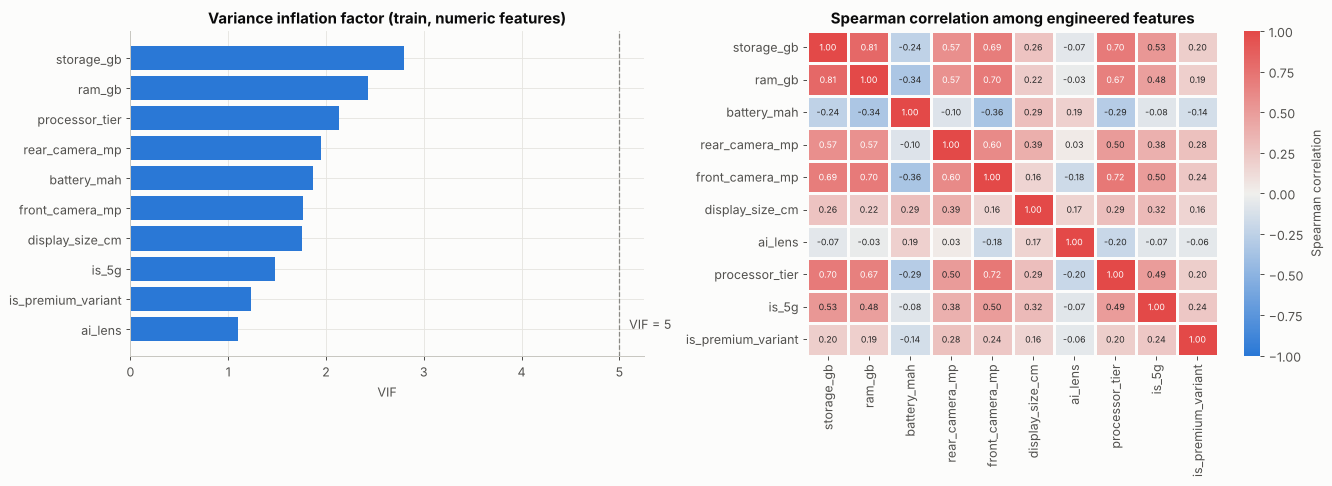

,storage_gb,ram_gb,processor_tier,rear_camera_mp,battery_mah,front_camera_mp,display_size_cm,is_5g,is_premium_variant,ai_lens
VIF,2.790,2.430,2.130,1.950,1.870,1.760,1.750,1.480,1.240,1.100


In [8]:
num_imp = fb[NUMERIC_FEATURES].fillna(fb[NUMERIC_FEATURES].median())
vif = variance_inflation_factors(num_imp)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(vif.index[::-1], vif.values[::-1], color=[ACCENT if v > 5 else PRIMARY for v in vif.values[::-1]])
axes[0].axvline(5, color=NEUTRAL, ls="--", lw=1); axes[0].text(5.1, 0, "VIF = 5", color="#52514e")
axes[0].set(title="Variance inflation factor (train, numeric features)", xlabel="VIF")
corr = num_imp.corr(method="spearman")
sns.heatmap(corr, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=axes[1], annot_kws={"size": 7},
            cbar_kws={"label": "Spearman correlation"}, linewidths=1, linecolor="#fcfcfb")
axes[1].set_title("Spearman correlation among engineered features"); axes[1].grid(False)
fig.tight_layout(); save_fig(fig, "fe_multicollinearity")
vif.round(2).to_frame("VIF").T

**Interpretation.** All VIFs are **below 3**, so multicollinearity is low to moderate. The pairwise heatmap still
shows a correlated cluster — storage, RAM, front camera and processor tier (premium phones upgrade them together), with
`is_5g` tied to tier — but no feature is a near-copy of another, so none is dropped as redundant. For the linear model we use **Ridge** (L2 regularisation), which
stabilises coefficients under collinearity. For interpretation, we'll use permutation importance and Shapley values,
and remember that correlated features share credit.

## 6. The reusable preprocessing pipeline
```
raw-ish inputs (model, processor, storage_gb, ram_gb, battery_mah, rear/front_camera_mp, ai_lens, display_size_cm)
   └─ SpecFeatureBuilder      stateless: brand, vendor, tier, is_5g, is_premium_variant
       └─ ColumnTransformer   fitted on TRAINING data only
            ├─ numeric:     median imputation (+ StandardScaler for linear models only)
            └─ categorical: 'Unknown' imputation → one-hot(min_frequency=5, unseen → infrequent)
```

In [9]:
prep = make_preprocessor(scale_numeric=False)
X_tr_enc = prep.fit_transform(X_tr)
print("Encoded training matrix:", X_tr_enc.shape)
print(list(X_tr_enc.columns))

Encoded training matrix: (419, 29)
['storage_gb', 'ram_gb', 'battery_mah', 'rear_camera_mp', 'front_camera_mp', 'display_size_cm', 'ai_lens', 'processor_tier', 'is_5g', 'is_premium_variant', 'brand_Apple', 'brand_Google', 'brand_Infinix', 'brand_Motorola', 'brand_OPPO', 'brand_POCO', 'brand_Redmi', 'brand_Samsung', 'brand_Tecno', 'brand_realme', 'brand_vivo', 'brand_infrequent_sklearn', 'processor_vendor_Apple', 'processor_vendor_Google Tensor', 'processor_vendor_MediaTek', 'processor_vendor_Qualcomm', 'processor_vendor_Samsung Exynos', 'processor_vendor_Unisoc', 'processor_vendor_Unknown']


In [10]:
# Safety checks: unseen brand, unknown processor, missing RAM at prediction time.
new_phones = pd.DataFrame([
    {"model": "Xiaomi 14 Civi", "processor": "Snapdragon 8s Gen 3", "storage_gb": 256, "ram_gb": 12,
     "battery_mah": 4700, "rear_camera_mp": 50, "front_camera_mp": 32, "ai_lens": 0, "display_size_cm": 16.9},
    {"model": "Acme Phone X", "processor": "Mystery Chip", "storage_gb": 128, "ram_gb": np.nan,
     "battery_mah": 5000, "rear_camera_mp": 50, "front_camera_mp": 8, "ai_lens": 0, "display_size_cm": 16.7},
])
enc_new = prep.transform(new_phones)
enc_new.loc[:, (enc_new != 0).any()]

,storage_gb,ram_gb,battery_mah,rear_camera_mp,front_camera_mp,display_size_cm,processor_tier,brand_infrequent_sklearn,processor_vendor_Qualcomm,processor_vendor_Unknown
0,256.000,12.000,"4,700.000",50.000,32.000,16.900,3.000,1.000,1.000,0.000
1,128.000,6.000,"5,000.000",50.000,8.000,16.700,1.000,1.000,0.000,1.000


**Interpretation.** Unseen brands (“Xiaomi”, “Acme”) go into `brand_infrequent_sklearn` instead of raising an error;
a newer chip (“Snapdragon 8s Gen 3”) is still recognised as flagship tier (3) by its name pattern; an unrecognised chip gets the training-median
tier and vendor “Unknown”; missing RAM gets the training median. The pipeline can safely handle inputs it hasn't seen.

## 7. Save processed datasets

In [11]:
out = PROJECT_ROOT / "data" / "processed"
model_ready = pd.concat([train.assign(split="train"), test.assign(split="test")]).sort_index()
model_ready.to_csv(out / "phones_model_ready.csv", index=False)

features_train = SpecFeatureBuilder().transform(train[MODEL_INPUT_COLUMNS]).assign(price=train[TARGET].values, model_key=train[GROUP_KEY].values)
features_train.to_csv(out / "features_train.csv", index=False)
print("Saved:", [p.name for p in sorted(out.iterdir())])
print(model_ready["split"].value_counts().to_dict())

Saved: ['cleaning_log.csv', 'excluded_rows.csv', 'features_train.csv', 'phones_clean.csv', 'phones_model_ready.csv']
{'train': 419, 'test': 97}


## Summary
| Feature | Source | Encoding | Why |
|---|---|---|---|
| storage_gb, ram_gb, battery_mah, rear/front_camera_mp, display_size_cm, ai_lens | numeric columns | numeric (median-imputed) | already numeric; RAM has 15 NaNs |
| processor_tier | processor text | ordinal 0–3 | real order; strongest single signal in EDA |
| processor_vendor | processor text | one-hot | no order, 7 values |
| brand | model text | one-hot, rare pooled | strong price bands; unseen-safe |
| is_5g, is_premium_variant | model text | binary | generalisable naming signals |
| model, colour | — | **not used** | identifiers; hurt grouped CV |

The pipeline lives in `src/feature_engineering.py`; the split is saved in `data/processed/phones_model_ready.csv`.